# 10장 · LLM 답변의 주장과 근거 검증

답변을 검증할 때는 한 문장을 확인 가능한 주장으로 나누고 각 주장을 뒷받침하는 원문을 찾습니다.

시민 도서관 행사를 알릴 문안에 ‘예약은 12월 1일부터’라는 문장이 들어왔습니다. 날짜를 잘못 공지하지 않으려면 초안에서 주장 하나를 꺼내 원문의 어느 줄이 뒷받침하는지 확인해야 합니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## 주장과 출처 문장 대응

가상 원문에 줄 번호를 매겨 두면 다른 사람이 어디를 확인해야 하는지 알 수 있습니다. 자료 이름까지 함께 남겨 같은 번호가 다른 문서를 가리키는 일을 막습니다.


### 셀 01 · 원문에서 정원 근거 추출

원문 3행에서 학생이 확인할 수 있는 사실을 읽으세요.


In [1]:
brief = """가상 시민 도서관 행사 안내 초안
독서 체험 행사는 12월 12일 14시에 시작하며 16시에 끝난다.
참가 대상은 성인 20명이다. 참가비는 없다.
행사장은 본관 2층 세미나실이다.
예약 시작일과 신청 링크는 아직 정하지 않았다.
담당자가 최종 확인하기 전에는 외부에 게시하지 않는다."""
lines = brief.splitlines()
print(lines[2])

참가 대상은 성인 20명이다. 참가비는 없다.


성인 20명과 무료 참가비가 나옵니다. 원문의 줄 번호는 1부터, 리스트 인덱스는 0부터 세므로 3행을 읽을 때는 [2]를 씁니다.


### 셀 02 · 예약일 주장의 근거 검사

초안이 ‘예약은 12월 1일부터’라고 했습니다. 신청 관련 원문을 직접 고릅니다.


In [2]:
claim = "예약은 12월 1일부터"
source_line = next(line for line in lines if "예약 시작일" in line)
print(source_line)

예약 시작일과 신청 링크는 아직 정하지 않았다.


시작일과 링크는 아직 정하지 않았습니다. 날짜를 지울 때는 예약 제도 자체까지 지우지 말고 확인된 상태를 밝혀 주세요.


## 근거 부재와 미확정 정보 구분

‘예약 날짜는 미정이다’는 원문 상태를 전달하는 문장입니다. 반면 ‘12월 1일부터 예약 가능’은 이 자료에서 뒷받침할 수 없습니다. 같은 항목이어도 기록할 상태가 다릅니다.

<!-- lesson-visual detail-record -->
**좌석 30석을 행사 정원 30명으로 써도 될까요?**

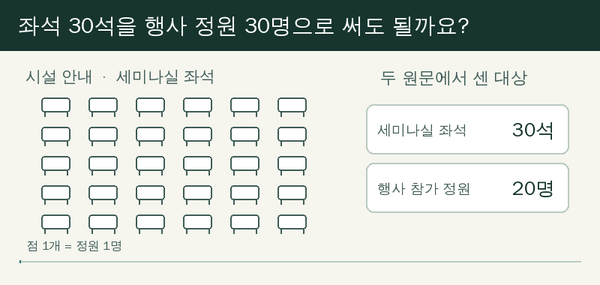

시설 안내에 있는 좌석을 모두 그리면 30석입니다. 행사 안내가 허용한 성인 참가자 20명을 점으로 표시하면 10석이 남습니다. 점은 실제 예약 현황이 아니라 행사 정원을 나타냅니다.
<!-- /lesson-visual detail-record -->


### 과제 03 · 검증된 사실과 출처 기록

행사장의 위치를 claim, source, location, status로 기록하고 위치가 든 근거를 출력하세요.

신청 링크 행은 두 칸으로 판단합니다. ‘원문 근거’에는 5행에서 링크 안내를 확인했다고 쓰고, ‘실제 URL’에는 아직 미정이라고 씁니다. 원문에 안내가 있다는 사실만으로 링크 주소를 채울 수는 없습니다.


In [3]:
row = {}
# 행사장 위치 한 건을 기록하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>row = {&quot;claim&quot;: &quot;본관 2층 세미나실&quot;, &quot;source&quot;: &quot;brief.txt&quot;, &quot;location&quot;: &quot;4행&quot;, &quot;status&quot;: &quot;confirmed&quot;}
print(row[&quot;location&quot;], lines[3])</code></pre>
<p>실행 결과</p><pre><code>4행 행사장은 본관 2층 세미나실이다.</code></pre>
<p>4행에서 건물, 층, 공간 이름을 모두 확인할 수 있습니다. 초안의 주장을 자료에서 찾지 못하면 그럴듯한 줄 번호를 채우지 않습니다.</p>
</details>


#### 원문 간 수치의 대상 비교

<div class="demo-panels"><div><small>가상 행사 안내 · 참가 대상</small><h4>모집 정원의 원문 근거</h4><p>이번 행사에서 신청을 받는 인원</p></div><div><small>가상 시설 안내 · 본관 2층</small><h4>시설 수용 인원의 원문 근거</h4><p>행사장에 설치된 좌석 수</p></div></div><p>신청 인원을 안내하는 문장에는 어느 자료의 숫자가 들어가는지 짚어 보세요.</p>


### 셀 04 · 문서 간 수치의 의미 비교

아래 시설 카드도 수업용 가상 자료입니다. 세미나실에 30명이 앉을 수 있다는 문장을 읽고, 행사 정원을 30명으로 고칠 근거인지 판단하세요.


In [4]:
facility = {"자료": "가상 시설 안내", "위치": "세미나실 항목", "내용": "본관 2층 세미나실 좌석은 30석이다."}
print(lines[2])
print(facility["내용"])

참가 대상은 성인 20명이다. 참가비는 없다.
본관 2층 세미나실 좌석은 30석이다.


20명은 이번 행사에서 받을 인원이고 30석은 방의 좌석 수입니다. 두 숫자를 비교하려면 먼저 항목이 같은지 확인해야 합니다. 출처를 한 건 더 찾았어도 정원을 바꿀 근거는 생기지 않았습니다.


## 게시 전 검토 기준과 인계

초안을 정리한 일과 외부에 게시하기로 결정한 일은 별개입니다. 확인자가 읽을 문안에는 미정 정보, 원문 위치, 필요한 다음 행동을 짧게 담습니다. 개인정보가 있는 원본은 실습 서비스에 붙여넣지 않습니다.


### 과제 05 · 미확인 주장의 검토 요청

신청일과 링크를 기다리는 담당자에게 지금 무엇을 확인해야 하는지 한 문장으로 써 보세요.


In [5]:
# 확정해야 할 항목과 근거 위치를 쓰세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>print(&quot;brief.txt 5행의 예약 시작일과 신청 링크는 미정입니다. 게시 전 두 값을 담당자에게 확인해 주세요.&quot;)</code></pre>
<p>실행 결과</p><pre><code>brief.txt 5행의 예약 시작일과 신청 링크는 미정입니다. 게시 전 두 값을 담당자에게 확인해 주세요.</code></pre>
<p>일정을 지어내지 않고 확인할 사람과 항목을 정했습니다. 브라우저 대화나 API로 초안을 얻더라도 게시 책임과 원문 확인 절차는 같습니다.</p>
</details>


## 돌아보기

‘성인 20명’, ‘12월 1일 예약’, ‘신청 링크 미정’을 다시 읽어 보세요. 확인된 숫자, 근거 없는 숫자, 원문이 밝힌 미정 상태를 각각 설명할 수 있으면 어떤 부분을 담당자에게 넘길지 판단할 수 있습니다.

### 안내문이 게시되기 전의 확인

**자료와 목적 확인**　업로드 가능한 가상 자료만 선택합니다.

```
brief.txt
```

**자료를 정리합니다**　확정 정보와 미확정 정보를 구분합니다.

```
draft
```

**주장별 근거를 검사합니다**　일정·대상·비용·장소를 원문과 비교합니다.

```
evidence.csv · 주장과 근거를 나란히 적는 기록 예시
```

**미확정 정보를 확인합니다**　확인 전에는 게시를 보류합니다.

```
확인 대기: 예약 시작일 · 신청 링크
```
